# Typhoon warnings and rice-price spikes (2024?2025)

> **Which Philippine regions experienced both heavy typhoon warnings (2024?2025) and unstable rice prices, and to what extent did those traits overlap?**

This descriptive exploratory analysis answers the question in three parts: **(1) the typhoon warnings, (2) sudden rice price rises, and (3) where typhoon-warned provinces overlap with price spikes**. It uses counts, shares, and medians only. It cannot establish that warnings changed prices.

| Part | Charts | Purpose |
|---|---|---|
| Typhoons | Chart 1 | Storm timing, storm type, and repeated severe listings |
| Prices | Chart 2 | National price path, regional price levels, and reporting rhythm |
| Overlap | Charts 3?4 | Single-panel warning and price-spike grids |
| Descriptive price view | Chart 5 | Province-level upside swing ranking |

In [1]:
from pathlib import Path
import sqlite3, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
PROJECT_ROOT=Path.cwd()
while not (PROJECT_ROOT/"data/processed/project.db").exists() and PROJECT_ROOT!=PROJECT_ROOT.parent: PROJECT_ROOT=PROJECT_ROOT.parent
DB=PROJECT_ROOT/"data/processed/project.db"; FIG=PROJECT_ROOT/"output/figures"; FIG.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"savefig.dpi":160,"font.size":10})
COL={"Most vulnerable":"#d73027","Exposed but stable":"#4575b4","High price swings, lower severe-warning exposure":"#fdae61","Low concern":"#abd9e9"}
MARK={"Most vulnerable":"o","Exposed but stable":"s","High price swings, lower severe-warning exposure":"^","Low concern":"D"}
BOX=list(COL)
with sqlite3.connect(f"file:{DB}?mode=ro",uri=True) as con:
    signals=pd.read_sql_query("select sid,season,name,issued_time,tcws_1,tcws_2,tcws_3,tcws_4,tcws_5 from province_signals",con)
    boundaries=pd.read_sql_query("select province,region,lat,lon from provincial_boundaries",con)
    prices=pd.read_sql_query("select province,phase,period_start,regular_milled_price from rice_prices",con)
signals.issued_time=pd.to_datetime(signals.issued_time); prices.period_start=pd.to_datetime(prices.period_start)
all_prov=boundaries.province.drop_duplicates().sort_values().tolist()
def split(x): return [] if pd.isna(x) or not str(x).strip() else [p.strip() for p in str(x).split(";") if p.strip()]
parts=[]
for lev in range(1,6):
    d=signals[["sid","season","name","issued_time",f"tcws_{lev}"]].copy(); d["province"]=d[f"tcws_{lev}"].map(split); d=d.explode("province").dropna(subset=["province"]); d["signal_level"]=lev; parts.append(d[["sid","season","name","issued_time","province","signal_level"]])
long=pd.concat(parts,ignore_index=True)
peak=long.groupby(["sid","province"],as_index=False).signal_level.max().rename(columns={"signal_level":"peak_signal"})
exposure=pd.DataFrame({"province":all_prov}).merge(peak.assign(severe=peak.peak_signal>=3).groupby("province").severe.sum().rename("n_severe"),on="province",how="left").fillna({"n_severe":0}).merge(boundaries,on="province")
exposure.n_severe=exposure.n_severe.astype(int)
months=pd.date_range("2024-01-01","2025-12-01",freq="MS")
monthly_warning=long.assign(month=long.issued_time.dt.to_period("M").dt.to_timestamp()).groupby("month").province.nunique().reindex(months,fill_value=0)
pw=prices.sort_values(["province","period_start","phase"])
price_wide=pw.pivot(index="province",columns="period_start",values="regular_milled_price").sort_index(axis=1)
price_wide=price_wide.loc[price_wide.notna().any(axis=1)]
monthly_wide=price_wide.loc[:,price_wide.columns.day==1]
def upside_swing(wide):
    rises=wide.pct_change(axis=1,fill_method=None).mul(100).clip(lower=0).fillna(0)
    return np.sqrt((rises.pow(2).sum(axis=1))/(wide.shape[1]-1))
upside=upside_swing(price_wide).rename("upside_swing")
upside_month=upside_swing(monthly_wide).rename("upside_month")
price_stats=pd.DataFrame({"upside_swing":upside,"upside_month":upside_month})
price_stats["total_change_pct"]=price_wide.apply(lambda r:(r.dropna().iloc[-1]/r.dropna().iloc[0]-1)*100,axis=1)
price_stats["reading_count"]=price_wide.notna().sum(axis=1)
def short(x):
    x=x.split("(",1)[1].split(")",1)[0] if "(" in x and ")" in x else x
    return x.replace(" Region","").replace(" Autonomous","").strip()
for d in (exposure,boundaries): d["region_short"]=d.region.map(short)
prov=exposure.merge(price_stats.reset_index(),on="province",how="inner")
region_exposure=exposure.groupby("region_short").agg(n_provinces=("province","size"),n_severe=("n_severe","median")).reset_index()
reg_prices=prov.groupby("region_short").agg(upside_swing=("upside_swing","median"),upside_month=("upside_month","median")).reset_index()
reg=region_exposure.merge(reg_prices,on="region_short")
def assign_boxes(d,measure):
    x_median=d.n_severe.median(); y_median=d[measure].median(); result=d.copy(); high_x=result.n_severe>x_median; high_y=result[measure]>y_median
    result["box"]=np.select([high_x&high_y,high_x&~high_y,~high_x&high_y],BOX[:3],default=BOX[3])
    return result,x_median,y_median
region_main,region_x_median,region_y_median=assign_boxes(reg,"upside_swing")
region_month,_,region_month_y_median=assign_boxes(reg,"upside_month")
prov_main,province_x_median,province_y_median=assign_boxes(prov,"upside_swing")
prov_month,_,province_month_y_median=assign_boxes(prov,"upside_month")
region_main=region_main.merge(region_month[["region_short","box"]].rename(columns={"box":"month_box"}),on="region_short")
prov_main=prov_main.merge(prov_month[["province","box"]].rename(columns={"box":"month_box"}),on="province")
region_main["robust"]=region_main.month_box.eq("Most vulnerable")
prov_main["robust"]=prov_main.month_box.eq("Most vulnerable")
region_price_counts=prov.groupby("region_short").province.size().rename("price_count")
region_mv_counts=prov_main[prov_main.box.eq("Most vulnerable")].groupby("region_short").province.size().rename("mv_count")
region_shares=region_price_counts.to_frame().join(region_mv_counts,how="left").fillna({"mv_count":0}); region_shares["share"]=region_shares.mv_count.astype(int).astype(str)+"/"+region_shares.price_count.astype(int).astype(str)
def rhythm_share(g):
    z=g.dropna(subset=["regular_milled_price"]).assign(month=lambda x:x.period_start.dt.to_period("M"))
    wide=z.pivot_table(index="month",columns="phase",values="regular_milled_price",aggfunc="first")
    if not {"1st","2nd"}.issubset(wide.columns): return np.nan
    return (wide["1st"].eq(wide["2nd"]) & wide[["1st","2nd"]].notna().all(axis=1)).mean()
rhythm=prices.groupby("province").apply(rhythm_share,include_groups=False)
# Storm timing and repeat-hit calculations use bulletin issue times.
storm_first=signals.groupby("sid")["issued_time"].min().rename("first_bulletin").reset_index(); storm_peak=peak.groupby("sid").peak_signal.max().rename("storm_peak").reset_index(); storms=storm_first.merge(storm_peak,on="sid",how="left").fillna({"storm_peak":0}); storms["month"]=storms.first_bulletin.dt.to_period("M").dt.to_timestamp(); storms["storm_type"]=np.select([storms.storm_peak.eq(0),storms.storm_peak.le(2)],["never warned","Signal 1-2 only"],default="Signal 3+")
storms_by_month=storms.groupby(["month","storm_type"]).size().unstack(fill_value=0).reindex(months,fill_value=0)
for typ in ["never warned","Signal 1-2 only","Signal 3+"]:
    if typ not in storms_by_month: storms_by_month[typ]=0
storms_by_month=storms_by_month[["never warned","Signal 1-2 only","Signal 3+"]]
first_severe=long[long.signal_level>=3].groupby(["sid","province"])["issued_time"].min().reset_index(name="first_severe").sort_values(["province","first_severe","sid"]); first_severe["previous_severe"]=first_severe.groupby("province").first_severe.shift(1); first_severe["repeat_hit"]=(first_severe.first_severe-first_severe.previous_severe).dt.days.le(14).fillna(False)
repeat_counts=first_severe.groupby("province").repeat_hit.sum().astype(int).rename("repeat_hits"); severe_counts=first_severe.groupby("province").size().astype(int).rename("n_severe"); frequent=pd.DataFrame({"n_severe":severe_counts,"repeat_hits":repeat_counts}).fillna(0).reset_index(); frequent=frequent[frequent.n_severe>=4].sort_values(["n_severe","repeat_hits","province"],ascending=[False,False,True])
print("Signals: long rows",len(long),"| expected 2717 |","MATCH" if len(long)==2717 else "DIFFERENT"); print("Provinces ever warned",peak.province.nunique(),"| expected 63 |","MATCH" if peak.province.nunique()==63 else "DIFFERENT"); print("Warned storms",peak.sid.nunique(),"of",signals.sid.nunique(),"| expected 29 of 41"); print("Province-storm pairs",len(peak),"| expected 568 |","MATCH" if len(peak)==568 else "DIFFERENT"); print("Peak counts levels 1..5",peak.peak_signal.value_counts().reindex(range(1,6),fill_value=0).tolist(),"| expected [260, 168, 75, 54, 11]"); print("Storms per month:",int((storms_by_month.sum(axis=1)>0).sum()),"of 24"); print("Repeat hits:",int(first_severe.repeat_hit.sum()),"across",int((repeat_counts>0).sum()),"provinces")
print("Price table shape:",price_wide.shape,"| expected (81, 48)"); print("Missing readings:",int(prices.regular_milled_price.isna().sum()),"in",int(prices.assign(missing=prices.regular_milled_price.isna()).groupby("province").missing.any().sum()),"provinces"); print("Provinces ending lower:",int((price_stats.total_change_pct<0).sum()),"of",len(price_stats)); print("Upside swing median:",round(upside.median(),2),"| monthly:",round(upside_month.median(),2)); print("Upside swing top five:",upside.sort_values(ascending=False).head().round(2).to_dict()); print("Reporting rhythm median/min/max:",round(rhythm.median(),2),round(rhythm.min(),2),round(rhythm.max(),2),"| >=0.9:",int((rhythm>=.9).sum()))

Signals: long rows 2717 | expected 2717 | MATCH
Provinces ever warned 63 | expected 63 | MATCH
Warned storms 29 of 41 | expected 29 of 41
Province-storm pairs 568 | expected 568 | MATCH
Peak counts levels 1..5 [260, 168, 75, 54, 11] | expected [260, 168, 75, 54, 11]
Storms per month: 14 of 24
Repeat hits: 28 across 16 provinces
Price table shape: (81, 48) | expected (81, 48)
Missing readings: 98 in 3 provinces
Provinces ending lower: 75 of 81
Upside swing median: 1.98 | monthly: 2.11
Upside swing top five: {'Masbate': 5.34, 'Batangas': 5.22, 'Marinduque': 4.97, 'Occidental Mindoro': 4.48, 'Aurora': 4.41}
Reporting rhythm median/min/max: 0.38 0.0 0.92 | >=0.9: 3


## Setup and Data checks

The database is opened read-only. Only `province_signals`, `provincial_boundaries`, and `rice_prices` are used. `typhoon_forecast` exists in the database but is not used. No CSV is read.

## Reshaping

The five wide signal columns are split into one row per province and bulletin. A province's peak signal is the highest level reached in any bulletin of a storm.


## Exposure

Exposure is `n_severe`: storms whose peak signal reached 3 or higher. Never-warned provinces count as zero. Chart 1 counts each storm once in the month of its first bulletin. Storm type is never warned, Signal 1?2 only, or Signal 3+ based on the highest signal listed for that storm. A repeat hit is a Signal 3+ storm whose first severe listing for a province is within 14 days of that province?s previous first severe listing; 14 days is a chosen default. Repeat hits use bulletin issue times and do not measure damage, recovery time, or storm strength.


## Price-spike measure

The only price measure is **upside swing**: percentage rises between consecutive readings, with falls set to zero, summarized as the root-mean-square rise across all 48 readings. The robustness check repeats the same formula on the 24 first-of-month readings. Sulu and Batanes have no price readings and are excluded.

In [2]:
def legend(ax):
    handles=[Line2D([0],[0],marker=MARK[x],color="none",markerfacecolor=COL[x],markeredgecolor="#333",markersize=8,label=x) for x in BOX]
    ax.legend(handles=handles,title="Box",frameon=False,fontsize=8,loc="upper center",bbox_to_anchor=(0.5,-0.13),ncol=2)
def display_x(z):
    x=z.n_severe.astype(float).to_numpy(); jittered=x.copy()
    for value in sorted(z.n_severe.unique()):
        positions=np.flatnonzero(x==value); order=np.argsort(z.iloc[positions].province.to_numpy()); offsets=np.linspace(-.18,.18,len(positions)); jittered[positions[order]]=value+offsets
    return pd.Series(jittered,index=z.index)
def add_labels(ax,d,label_col,only_most=True):
    labels=d[d.box.eq("Most vulnerable")] if only_most else d
    for _,r in labels.sort_values(["upside_swing",label_col]).iterrows():
        suffix=" \u2605" if r.robust else ""; ax.annotate(f"{r[label_col]}{suffix}",(r.n_severe,r.upside_swing),xytext=(0,-8),textcoords="offset points",ha="center",va="top",fontsize=8 if label_col=="region_short" else 7)

## Summary statistics

The overlap analysis covers 81 provinces with regular-milled rice price data. The median `n_severe` was **1 storm**. In plain language, a typical province reached Signal 3 or higher during one storm. The interquartile range was **0 to 3 storms**, meaning the middle half of provinces fell within that exposure band. The full range was **0 to 7 storms**, so some provinces had no severe-warning storms while the most exposed province had seven. The distribution was right-skewed (skewness **1.21**), which means most provinces had few severe-warning storms but a smaller group had much higher exposure.

The median upside swing was **1.98%**. In plain language, a typical province's upward price movements had a size of about 2% under this measure; falls are counted as zero. The interquartile range was **1.15% to 2.85%**, so the middle half of provinces had typical rises within that band. The full range was **0.35% to 5.34%**, showing that some provinces had much larger price swings than others. Upside swing was also right-skewed (skewness **0.73**), meaning most provinces had smaller typical rises while a few had larger swings. Masbate, Batangas, Marinduque, Occidental Mindoro, and Aurora were the five highest provinces. The 1.5-times-IQR rule identifies no formal outliers, so these high values are not automatically errors; they remain important observations when interpreting the overlap.

Together, these summaries show that most provinces had low-to-moderate warning exposure and price variation, while a smaller group had much higher exposure or price swings. Those differences are why the overlap screen highlights specific provinces rather than treating the national experience as uniform.


# Part 1: Typhoons

## Chart 1 ? Storm timing and repeat severe listings


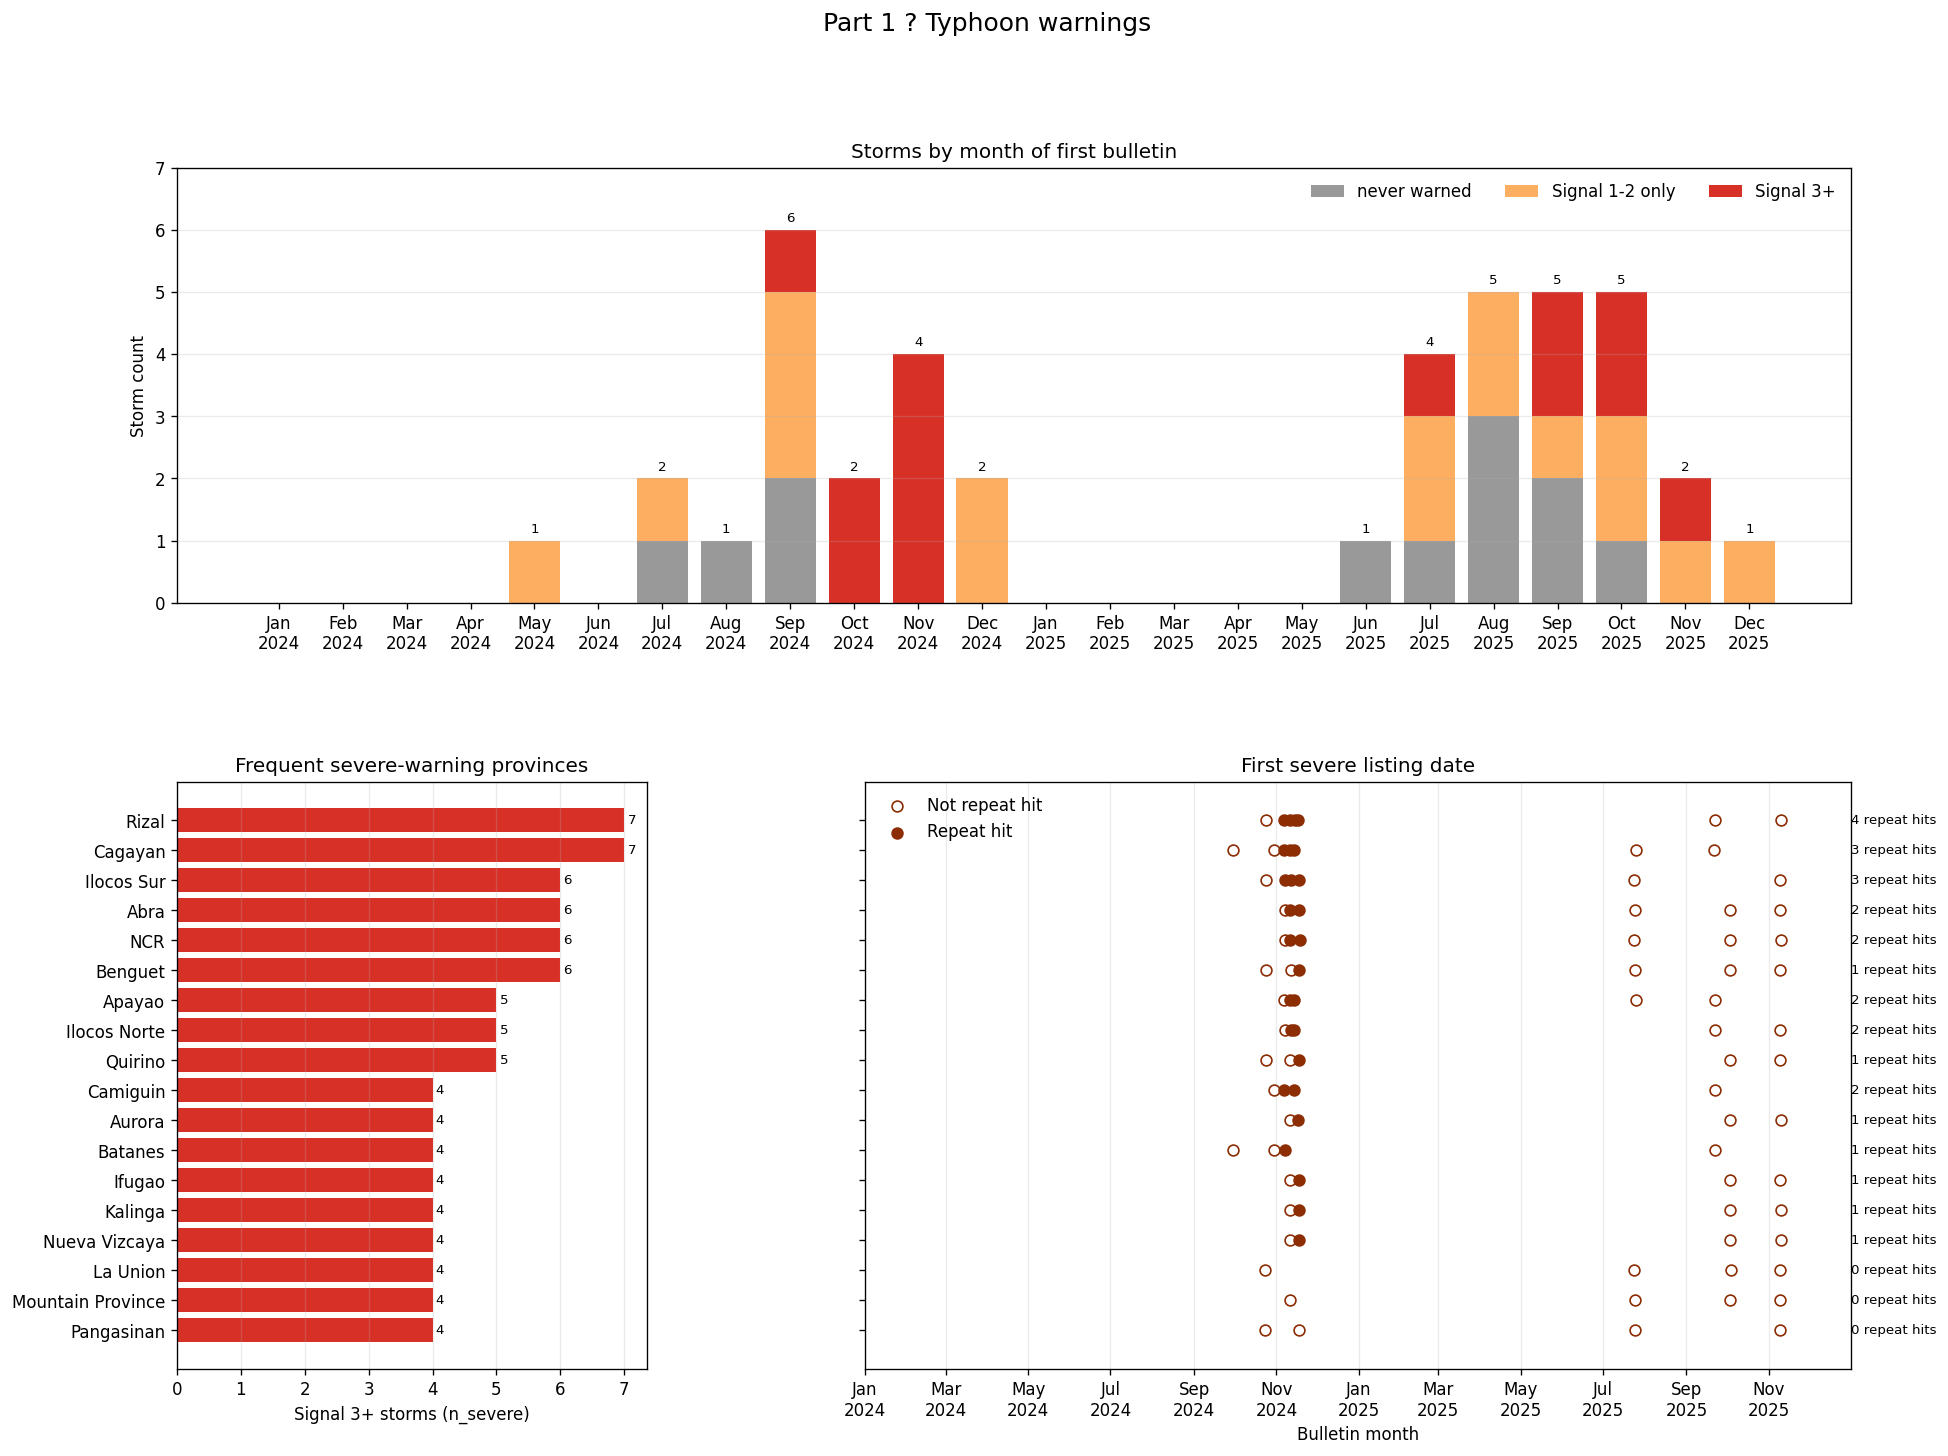

Peak signal counts levels 1-5: [260, 168, 75, 54, 11]
Warned storms: 29 of 41
Total repeat hits across all provinces: 28


In [3]:
from matplotlib.gridspec import GridSpec
fig=plt.figure(figsize=(18,13)); gs=GridSpec(2,2,figure=fig,height_ratios=[1,1.35],width_ratios=[1,2.1],hspace=.35,wspace=.3)
ax_top=fig.add_subplot(gs[0,:]); x=np.arange(len(months)); bottom=np.zeros(len(months)); storm_colors={"never warned":"#999999","Signal 1-2 only":"#fdae61","Signal 3+":"#d73027"}
for typ in ["never warned","Signal 1-2 only","Signal 3+"]:
    vals=storms_by_month[typ].to_numpy(); ax_top.bar(x,vals,bottom=bottom,color=storm_colors[typ],label=typ); bottom+=vals
for i,total in enumerate(bottom.astype(int)):
    if total: ax_top.text(i,total+.08,str(total),ha="center",va="bottom",fontsize=8)
ax_top.set(title="Storms by month of first bulletin",ylabel="Storm count",xticks=x,xticklabels=[m.strftime("%b\n%Y") for m in months]); ax_top.legend(frameon=False,ncol=3); ax_top.grid(axis="y",alpha=.25); ax_top.set_ylim(0,max(bottom)+1)
ax_bar=fig.add_subplot(gs[1,0]); rows=frequent.iloc[::-1]; y=np.arange(len(rows)); ax_bar.barh(y,rows.n_severe,color="#d73027"); ax_bar.set_yticks(y,rows.province); ax_bar.set(xlabel="Signal 3+ storms (n_severe)",title="Frequent severe-warning provinces"); ax_bar.grid(axis="x",alpha=.25)
for yi,(_,r) in zip(y,rows.iterrows()): ax_bar.text(r.n_severe+.05,yi,str(int(r.n_severe)),va="center",fontsize=8)
ax_time=fig.add_subplot(gs[1,1],sharey=ax_bar); ax_time.set_xlim(months.min(),months.max()+pd.offsets.MonthBegin(1)); ax_time.set_yticks(y,rows.province); ax_time.grid(axis="x",alpha=.25)
for yi,(_,r) in zip(y,rows.iterrows()):
    z=first_severe[first_severe.province.eq(r.province)]; ax_time.scatter(z.loc[~z.repeat_hit,"first_severe"],np.full((~z.repeat_hit).sum(),yi),facecolors="white",edgecolors="#8c2d04",s=42,zorder=3,label="Not repeat hit" if yi==0 else None); ax_time.scatter(z.loc[z.repeat_hit,"first_severe"],np.full(z.repeat_hit.sum(),yi),color="#8c2d04",s=42,zorder=4,label="Repeat hit" if yi==0 else None); ax_time.text(months.max()+pd.offsets.MonthBegin(1),yi,f'{int(r.repeat_hits)} repeat hits',va="center",fontsize=8)
ax_time.set(title="First severe listing date",xlabel="Bulletin month"); ax_time.legend(frameon=False,loc="upper left"); ax_time.tick_params(axis="y",labelleft=False); ax_time.set_xticks(months[::2]); ax_time.set_xticklabels([m.strftime("%b\n%Y") for m in months[::2]])
fig.suptitle("Part 1 ? Typhoon warnings",fontsize=15); fig.savefig(FIG/"chart1_typhoon_eda.png",bbox_inches="tight"); plt.show()
print("Peak signal counts levels 1-5:",peak.peak_signal.value_counts().reindex(range(1,6),fill_value=0).tolist()); print("Warned storms:",peak.sid.nunique(),"of",signals.sid.nunique()); print("Total repeat hits across all provinces:",int(first_severe.repeat_hit.sum()))

### Interpretation

Storms occurred in 14 of the 24 months, with none from January through April in either year. Signal 3+ storms first appeared in September, October, and November 2024, then July, September, October, and November 2025. The bottom rows show that Rizal and Cagayan had the most Signal 3+ storms at 7 each, followed by Ilocos Sur, NCR, and Abra at 6 each. There were 28 repeat hits across 16 provinces; Rizal had the most with 4, while Cagayan and Ilocos Sur had 3 each. Repeat hits are based on bulletin issue times and co-occur with earlier severe listings; they do not measure damage, recovery time, or storm strength.

**Link to the question:** For disaster planners, severe warnings were concentrated in particular storm periods and provinces. Repeated listings identify places that may deserve closer monitoring, but they do not measure damage or recovery.


# Part 2: Prices

## Chart 2 ? Price path and regional price spikes

The monthly national price is the median of all regular-milled readings from both phases in that month. The band is the 10th to 90th percentile. The regional bars show the median upside swing.

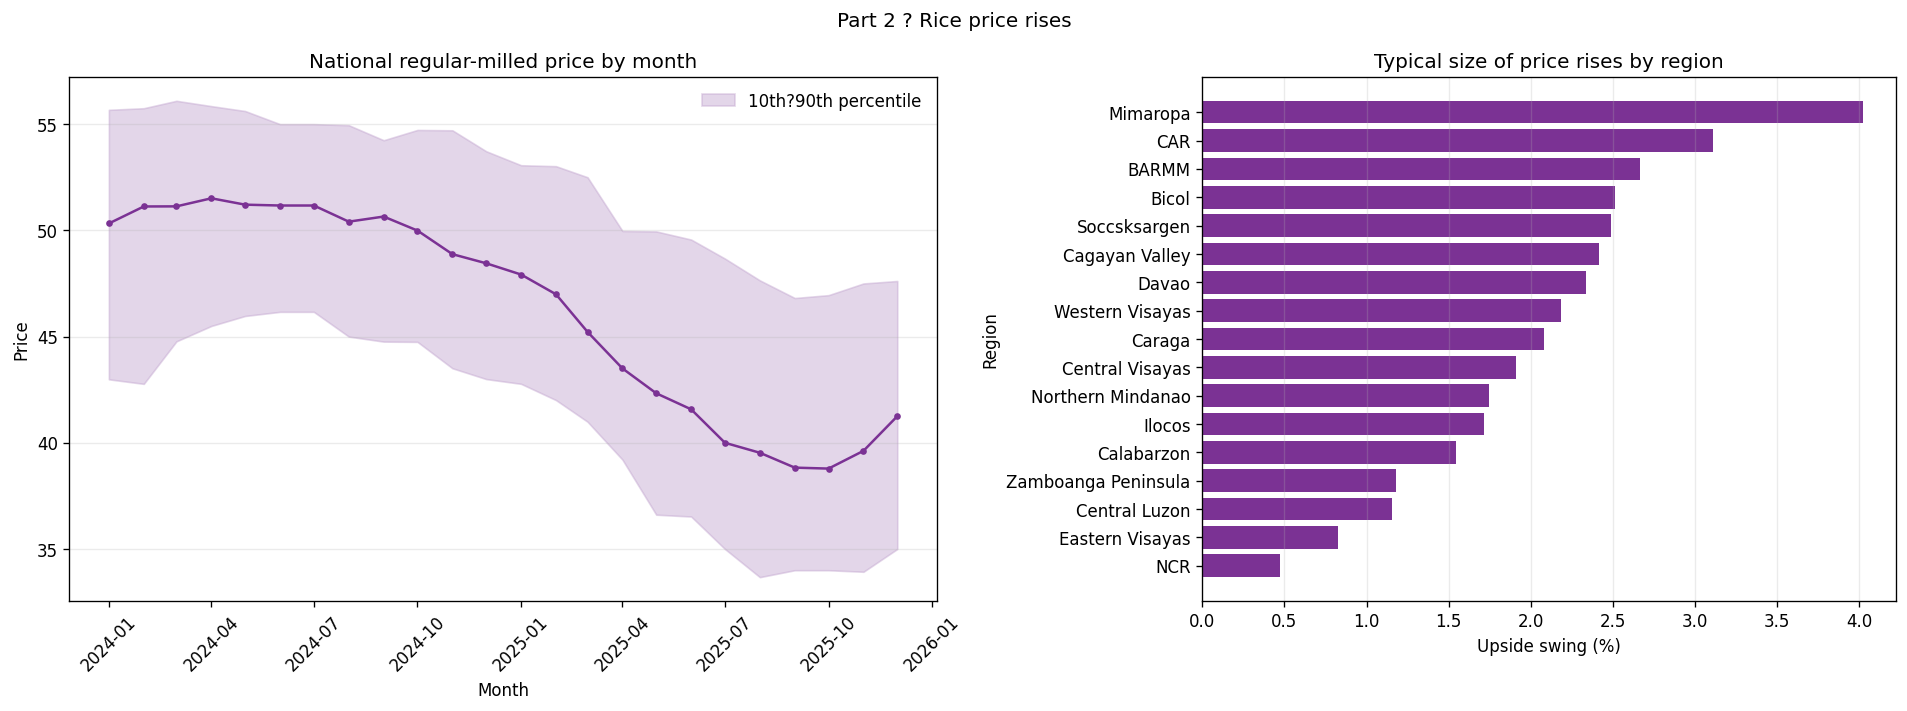

Provinces ending lower: 75 of 81
Median total percent change: -16.89
Missing readings by province: {'Batanes': 48, 'Misamis Occidental': 2, 'Sulu': 48}
Reporting rhythm median/min/max: 0.38 0.0 0.92 | >=0.9: 3
Jan24 median/band: 50.32 42.99 55.67
Oct25 median/band: 38.78 34.0 46.95


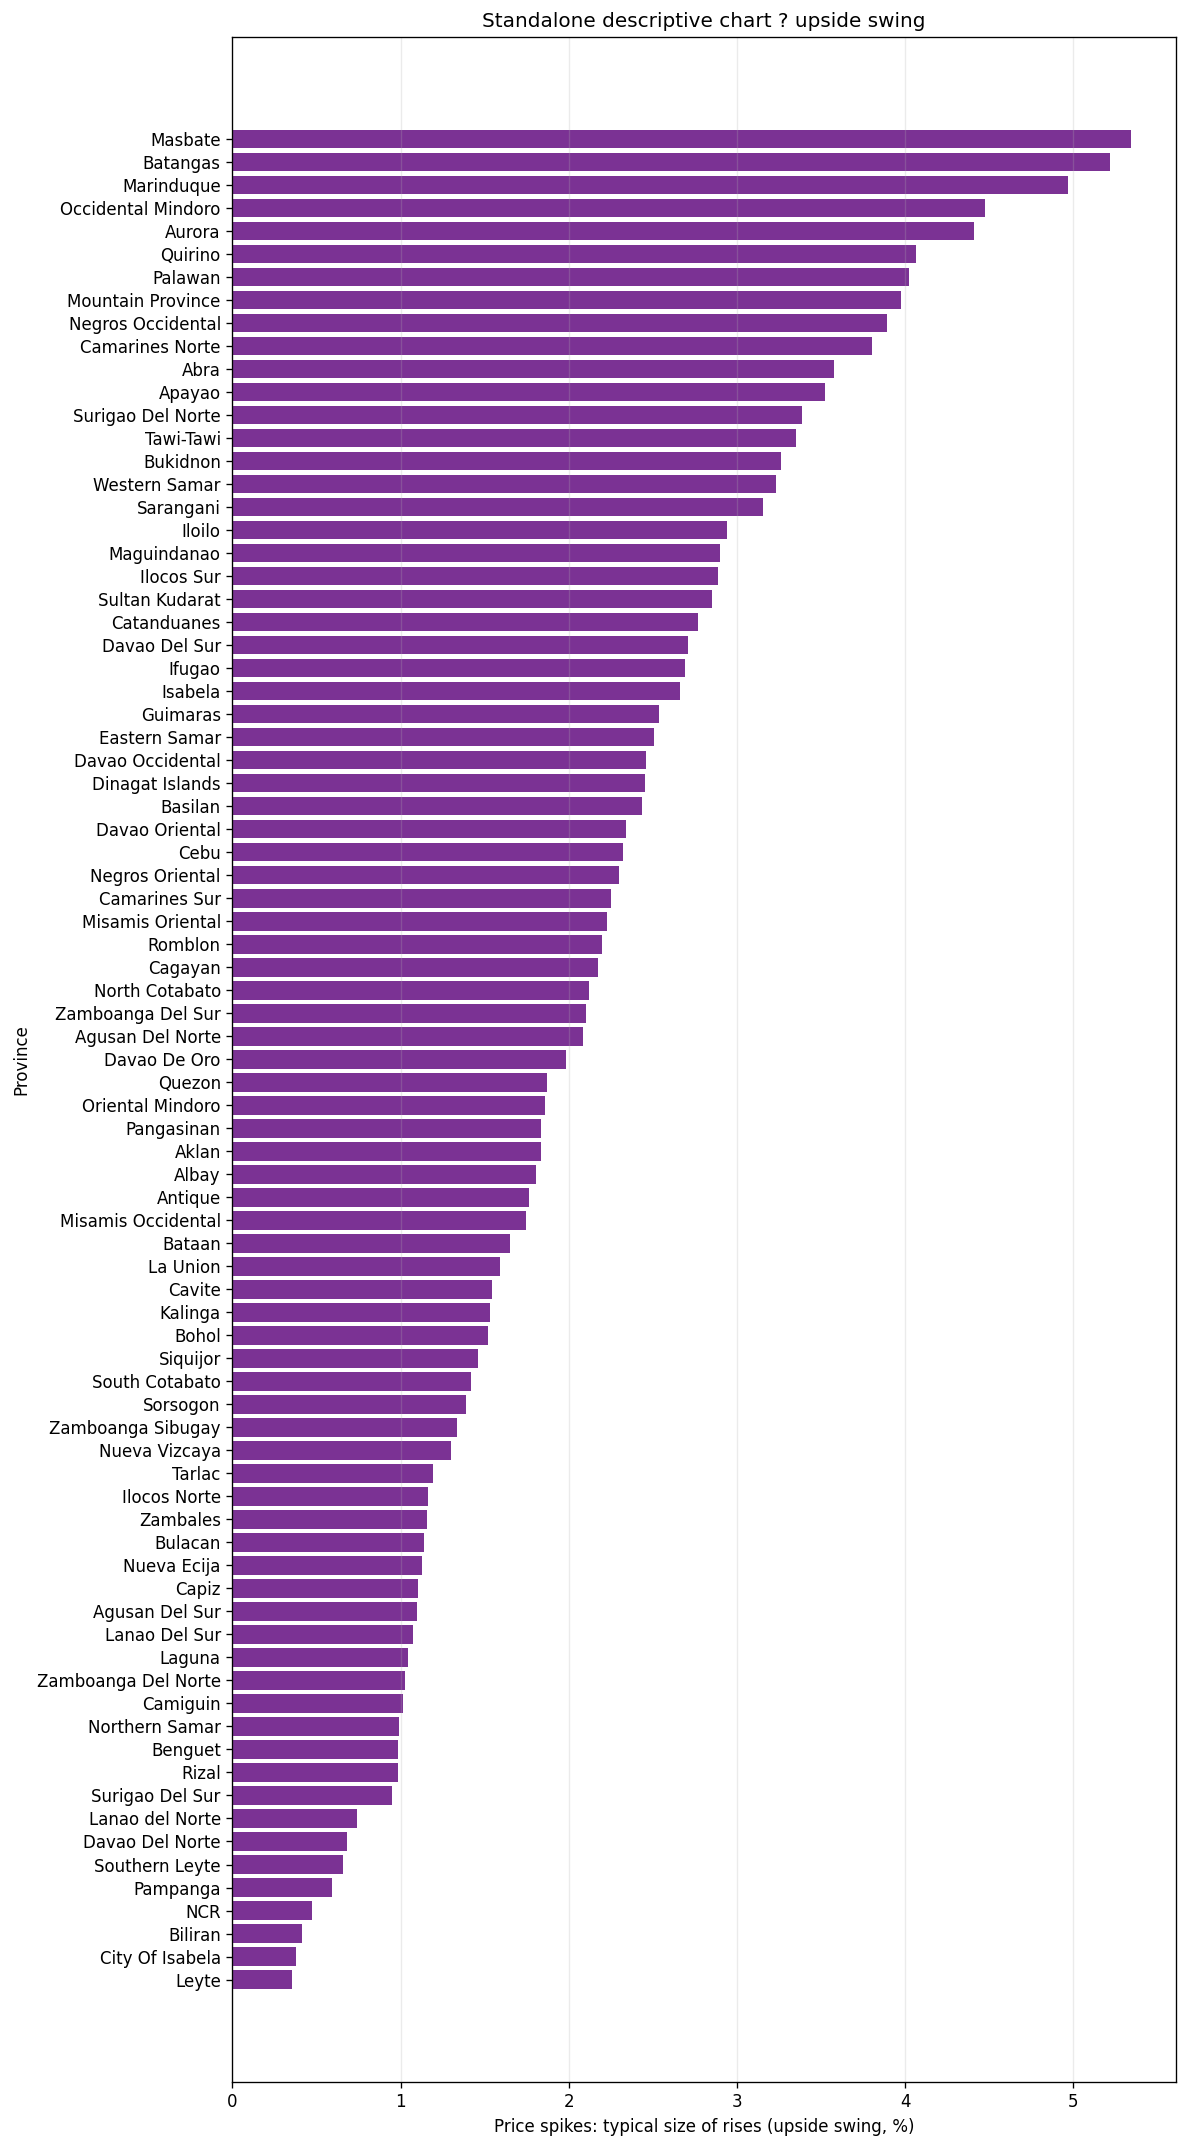

In [4]:
mp=pw.dropna(subset=["regular_milled_price"]).assign(month=lambda d:d.period_start.dt.to_period("M").dt.to_timestamp()).groupby("month").regular_milled_price.agg(median="median",p10=lambda x:x.quantile(.1),p90=lambda x:x.quantile(.9)).reindex(months)
fig,ax=plt.subplots(1,2,figsize=(16,6),gridspec_kw={"width_ratios":[1.25,1]}); ax[0].plot(months,mp["median"],color="#7b3294",marker="o",ms=3); ax[0].fill_between(months,mp.p10,mp.p90,color="#c2a5cf",alpha=.45,label="10th?90th percentile"); ax[0].set(title="National regular-milled price by month",xlabel="Month",ylabel="Price"); ax[0].tick_params(axis="x",rotation=45); ax[0].legend(frameon=False); ax[0].grid(axis="y",alpha=.25)
b=price_stats.groupby("province").size() if False else reg_prices.sort_values("upside_swing"); ax[1].barh(np.arange(len(b)),b.upside_swing,color="#7b3294"); ax[1].set_yticks(np.arange(len(b)),b.region_short); ax[1].set(title="Typical size of price rises by region",xlabel="Upside swing (%)",ylabel="Region"); ax[1].grid(axis="x",alpha=.25); fig.suptitle("Part 2 ? Rice price rises"); fig.tight_layout(); fig.savefig(FIG/"chart2_price_eda.png",bbox_inches="tight"); plt.show()
print("Provinces ending lower:",int((price_stats.total_change_pct<0).sum()),"of",len(price_stats)); print("Median total percent change:",round(price_stats.total_change_pct.median(),2)); print("Missing readings by province:",prices.assign(missing=prices.regular_milled_price.isna()).groupby("province").missing.sum().loc[lambda x:x>0].astype(int).to_dict()); print("Reporting rhythm median/min/max:",round(rhythm.median(),2),round(rhythm.min(),2),round(rhythm.max(),2),"| >=0.9:",int((rhythm>=.9).sum())); print("Jan24 median/band:",*[round(mp.loc["2024-01-01",x],2) for x in ["median","p10","p90"]]); print("Oct25 median/band:",*[round(mp.loc["2025-10-01",x],2) for x in ["median","p10","p90"]])
# Standalone descriptive view of upside swing.
bar_data=price_stats.sort_values("upside_swing",ascending=True)
fig,ax=plt.subplots(figsize=(10,18)); ax.barh(bar_data.index,bar_data.upside_swing,color="#7b3294"); ax.set(xlabel="Price spikes: typical size of rises (upside swing, %)",ylabel="Province",title="Standalone descriptive chart ? upside swing"); ax.grid(axis="x",alpha=.25); fig.tight_layout(); fig.savefig(FIG/"chart5_upside_swing.png",bbox_inches="tight"); plt.show()


### Interpretation

The national price fell for 75 of 81 provinces. Overall spread would partly measure that steady decline, so upside swing ignores falls and measures sudden rises. The reporting rhythm is uneven: some provinces repeat the same first- and second-phase price in most months, while others do not. This supports the interpretation that unstable means sudden price rises, not rising prices overall.

**Link to the question:** For food-security planners, price movements were not uniform across regions. The differences support monitoring local price conditions rather than relying only on a national trend.

## Chart 5 ? Province-level upside swing ranking

### Interpretation

Chart 5 isolates the price measure from storm exposure and ranks all provinces by the typical size of their price rises. Masbate, Batangas, Marinduque, Occidental Mindoro, and Aurora have the highest all-reading upside swing values. This descriptive ranking explains which provinces contribute the strongest price-spike signals before those values are combined with severe-warning exposure in Charts 3 and 4.

**Link to the question:** The largest price swings are concentrated in a small set of provinces. Planners can use this ranking to prioritize local investigation, while remembering that it does not identify the causes of the increases.

# Part 3: Overlap

A unit is high only when strictly above the median across units. Province grids use a display-only vertical line at 1.5 and deterministic jitter that never crosses it. Boxes are: Most vulnerable = red circle; Exposed but stable = blue square; High price swings, lower severe-warning exposure = orange triangle; Low concern = light-blue diamond. A star marks a unit that is also Most vulnerable under the one-reading-per-month check.

## Chart 3 ? Regional grid

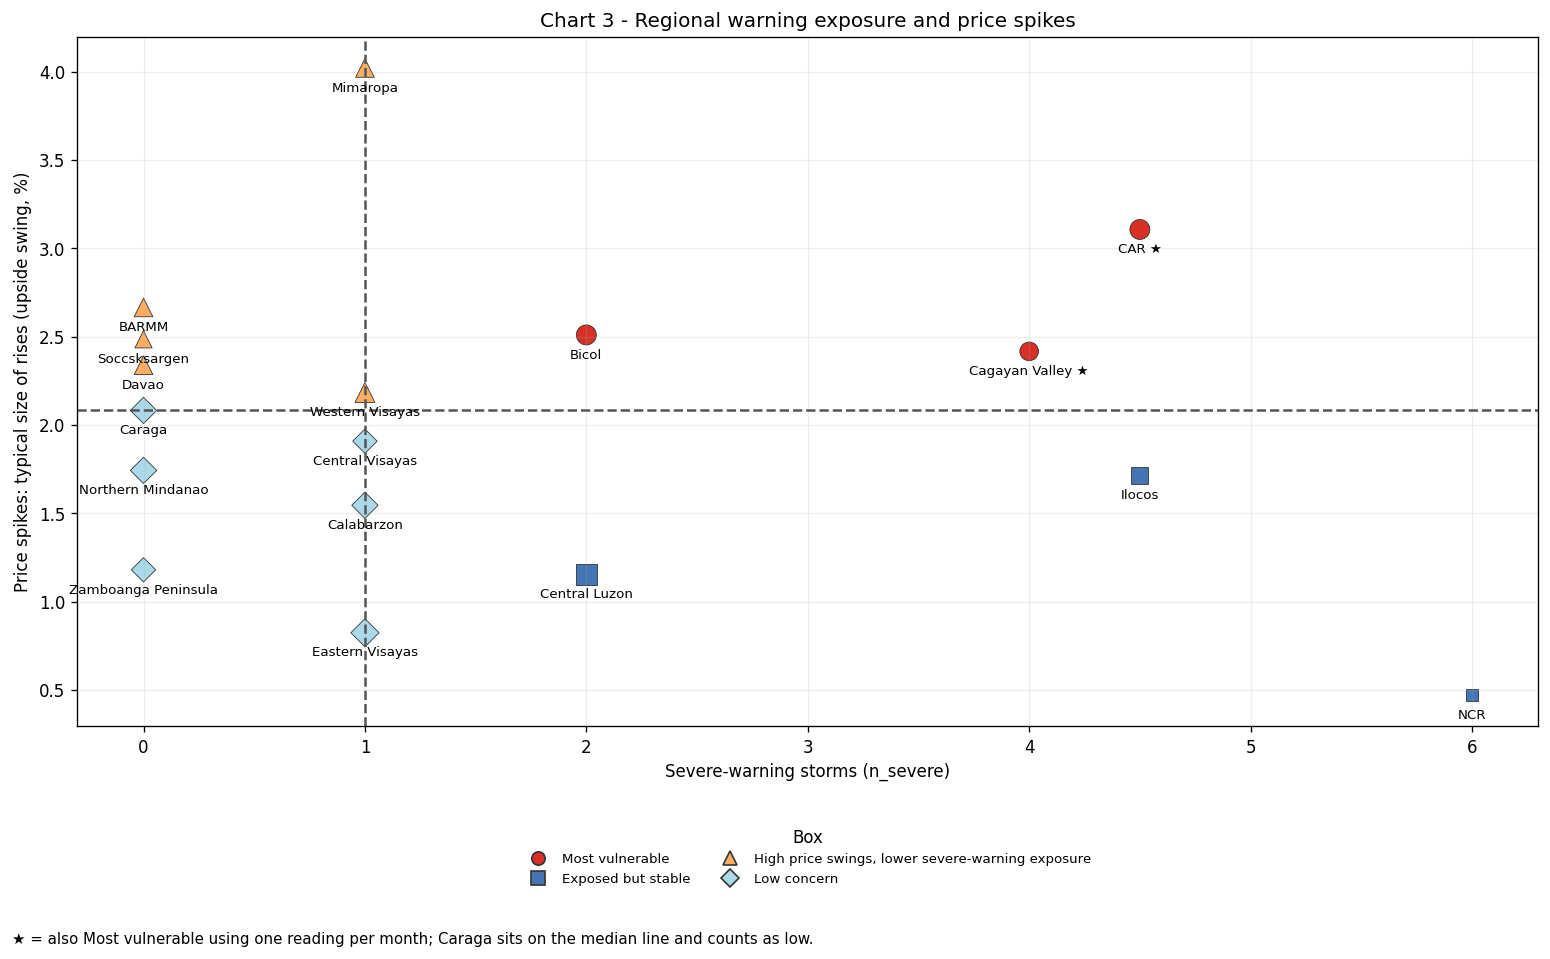

Regional scorecard:
       region_short  n_provinces  n_severe  median_upside_swing                                              box  also_most_vulnerable_monthly
              Bicol            6       2.0             2.509967                                  Most vulnerable                         False
                CAR            6       4.5             3.106921                                  Most vulnerable                          True
     Cagayan Valley            5       4.0             2.416746                                  Most vulnerable                          True
              BARMM            5       0.0             2.665613 High price swings, lower severe-warning exposure                         False
         Calabarzon            5       1.0             1.545492                                      Low concern                         False
             Caraga            5       0.0             2.082374                                      Low concern          

In [5]:
fig,ax=plt.subplots(figsize=(13,8)); ax=ax; ax.set_xlabel("Severe-warning storms (n_severe)"); ax.set_ylabel("Price spikes: typical size of rises (upside swing, %)"); ax.grid(alpha=.2)
for b in BOX:
    z=region_main[region_main.box.eq(b)]; ax.scatter(z.n_severe,z.upside_swing,s=35+18*z.n_provinces,color=COL[b],marker=MARK[b],edgecolor="#333",linewidth=.5)
ax.axvline(region_x_median,color="#555",ls="--"); ax.axhline(region_y_median,color="#555",ls="--"); ax.set_title("Chart 3 - Regional warning exposure and price spikes")
add_labels(ax,region_main,"region_short",only_most=False); legend(ax); fig.text(.01,.01,"\u2605 = also Most vulnerable using one reading per month; Caraga sits on the median line and counts as low.",fontsize=9); fig.tight_layout(rect=[0,0.04,1,1]); fig.savefig(FIG/"chart3_regional_grid.png",bbox_inches="tight"); plt.show()
score=region_main[["region_short","n_provinces","n_severe","upside_swing","box","robust"]].rename(columns={"upside_swing":"median_upside_swing","robust":"also_most_vulnerable_monthly"}).copy(); score["share"]=score.region_short.map(region_shares.share); score["_order"]=score.box.eq("Most vulnerable").map({True:0,False:1}); score=score.sort_values(["_order","region_short"]).drop(columns="_order"); print("Regional scorecard:"); print(score[["region_short","n_provinces","n_severe","median_upside_swing","box","also_most_vulnerable_monthly"]].to_string(index=False)); print("Most vulnerable provinces by region (k/n with price data):"); print(region_shares["share"].to_string()); print("Regional borderline:",region_main.loc[(region_main.upside_swing-region_y_median).abs()<=.01,"region_short"].tolist())

### Interpretation

The single regional panel shows exposure against typical upside price spikes. Bicol, CAR, and Cagayan Valley are Most vulnerable in the all-reading version; CAR and Cagayan Valley carry stars because they remain Most vulnerable under one reading per month, while Bicol does not. Caraga sits on the median line and counts as low.

**Link to the question:** Bicol, CAR, and Cagayan Valley are the main regional screening priorities because they combine above-median severe-warning exposure and price swings. CAR and Cagayan Valley remain priorities in the monthly robustness check.

## Chart 4 ? Province grid

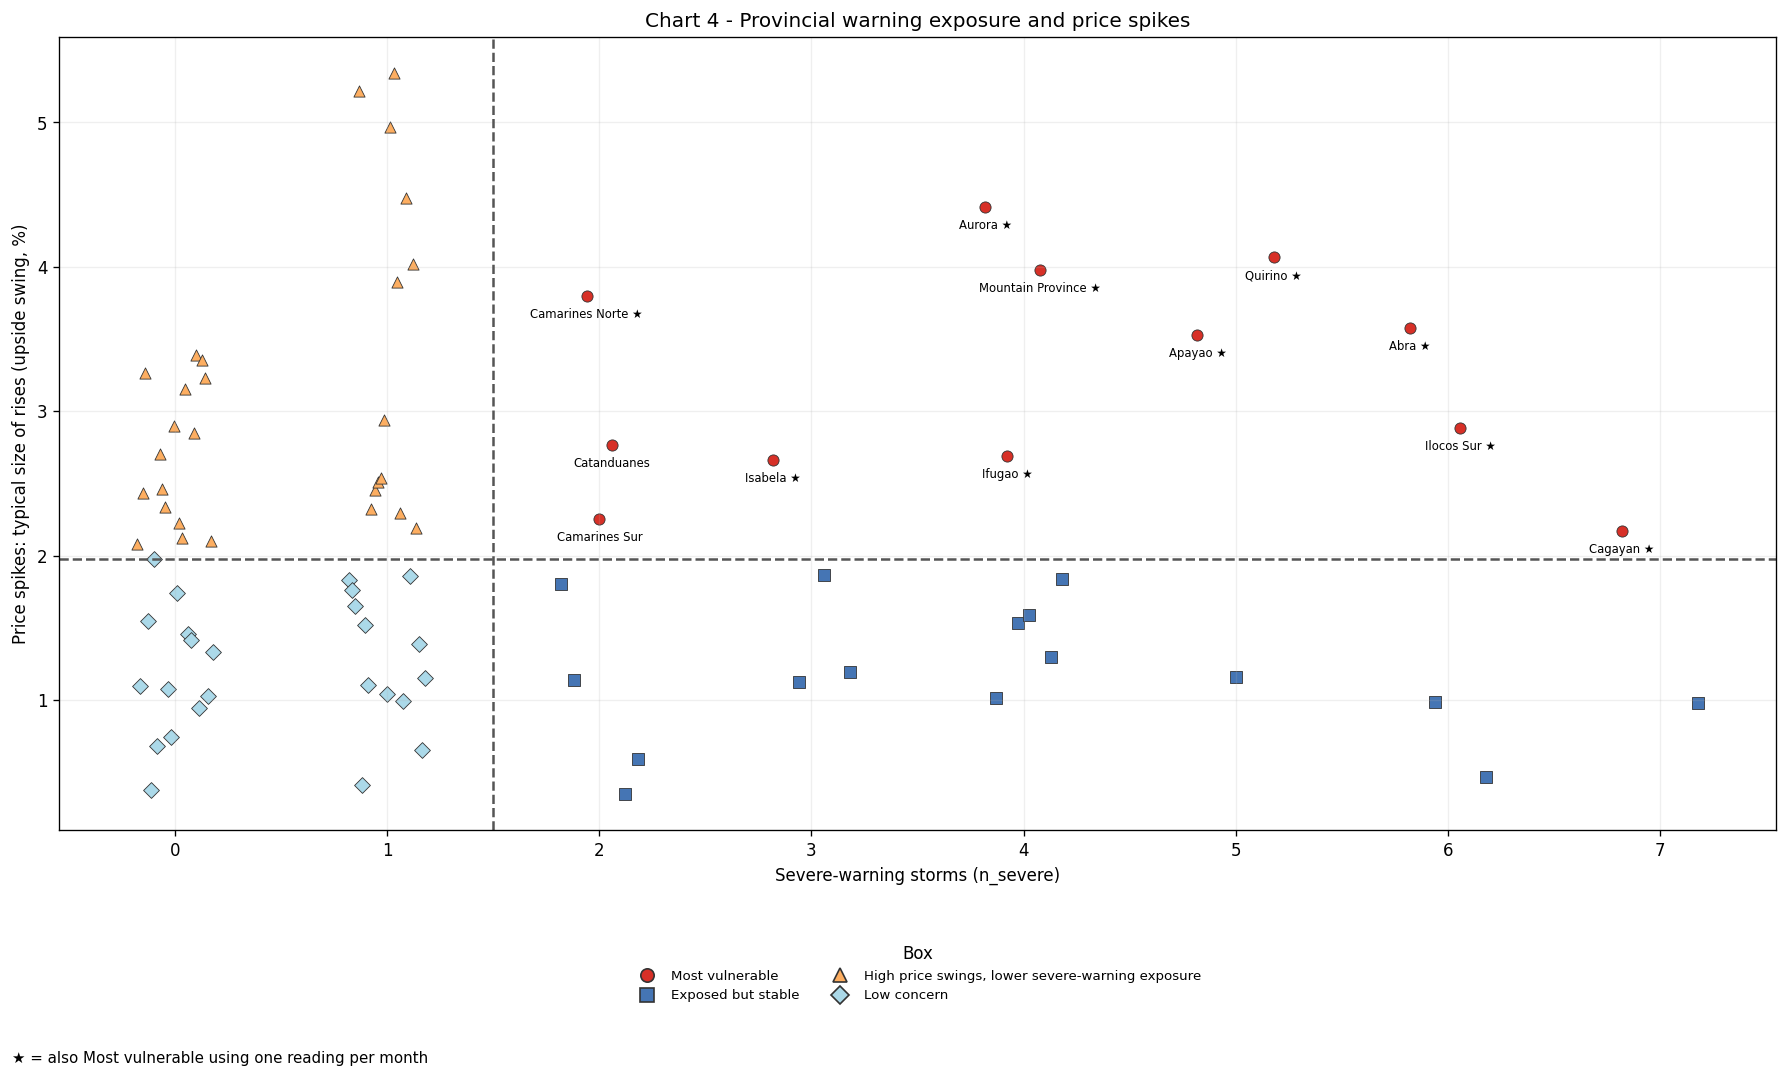

All provinces:
           province        region_short  n_severe upside_swing                                              box  also_most_vulnerable_monthly
            Cagayan      Cagayan Valley         7         2.17                                  Most vulnerable                          True
               Abra                 CAR         6         3.57                                  Most vulnerable                          True
         Ilocos Sur              Ilocos         6         2.89                                  Most vulnerable                          True
             Apayao                 CAR         5         3.53                                  Most vulnerable                          True
            Quirino      Cagayan Valley         5         4.06                                  Most vulnerable                          True
             Aurora       Central Luzon         4         4.41                                  Most vulnerable                      

In [6]:
fig,ax=plt.subplots(figsize=(15,9)); ax.set_xlabel("Severe-warning storms (n_severe)"); ax.set_ylabel("Price spikes: typical size of rises (upside swing, %)"); ax.grid(alpha=.2)
display_positions=display_x(prov_main)
for b in BOX:
    z=prov_main[prov_main.box.eq(b)]; ax.scatter(display_positions.loc[z.index],z.upside_swing,s=45,color=COL[b],marker=MARK[b],edgecolor="#333",linewidth=.5)
ax.axvline(1.5,color="#555",ls="--"); ax.axhline(province_y_median,color="#555",ls="--"); ax.set_title("Chart 4 - Provincial warning exposure and price spikes")
labels=prov_main[prov_main.box.eq("Most vulnerable")].sort_values(["upside_swing","province"])
for idx,r in labels.iterrows():
    suffix=" \u2605" if r.robust else ""; ax.annotate(f"{r.province}{suffix}",(display_positions.loc[idx],r.upside_swing),xytext=(0,-7),textcoords="offset points",ha="center",va="top",fontsize=7)
legend(ax); fig.text(.01,.01,"\u2605 = also Most vulnerable using one reading per month",fontsize=9); fig.tight_layout(rect=[0,0.04,1,1]); fig.savefig(FIG/"chart4_provincial_grid.png",bbox_inches="tight"); plt.show()
province_table=prov_main[["province","region_short","n_severe","upside_swing","box","robust"]].rename(columns={"robust":"also_most_vulnerable_monthly"}); order={b:i for i,b in enumerate(BOX)}; province_table=province_table.assign(_order=province_table.box.map(order)).sort_values(["_order","n_severe","province"],ascending=[True,False,True]).drop(columns="_order"); print("All provinces:"); print(province_table.to_string(index=False,formatters={"upside_swing":"{:.2f}".format})); print("Robustness check summary:"); print("Same box:",int((prov_main.box==prov_main.month_box).sum()),"of",len(prov_main),"provinces"); print("Most vulnerable under one reading per month:",sorted(prov_main.loc[prov_main.month_box.eq("Most vulnerable"),"province"].tolist()))

### Interpretation

The single provincial panel shows all 81 price-covered provinces, while labels are limited to the 12 Most vulnerable provinces. The all-reading Most vulnerable list is Abra, Apayao, Aurora, Cagayan, Camarines Norte, Camarines Sur, Catanduanes, Ifugao, Ilocos Sur, Isabela, Mountain Province, and Quirino. Stars identify the 10 that remain Most vulnerable under one reading per month; Camarines Sur and Catanduanes do not.

**Link to the question:** For food-security planners, the 12 Most vulnerable provinces are candidates for closer monitoring because they combine relatively high severe-warning exposure with larger price rises. Ten remain in that screening group under the monthly check, but the result does not show that warnings caused the price increases.


## Cautious inference

The data show that some provinces had both more severe-warning exposure and larger rice-price swings, especially in Bicol, CAR, and Cagayan Valley. A possible explanation is that these provinces may share conditions such as local supply constraints, transport disruption, market remoteness, or different price-reporting coverage. The available data cannot determine which explanation is responsible, and warnings should not be treated as a measure of physical damage.

**Plain-language hypothesis:** Provinces with greater exposure to severe storms may also face conditions that make rice prices more variable, but the apparent relationship may be explained by other geographic, market, or data-coverage factors.

**Confidence:** Low. This analysis is purely descriptive: its purpose is to uncover and describe patterns that may deserve further investigation, not to prove cause and effect. It covers only two years, uses descriptive medians rather than causal tests, and does not include damage, transport, inventory, supply, demand, or intervention variables.


In [7]:
print("Robustness check summary:"); print("Same box: regions",int((region_main.box==region_main.month_box).sum()),"of",len(region_main),"; provinces",int((prov_main.box==prov_main.month_box).sum()),"of",len(prov_main)); print("Most vulnerable regions under one reading per month:",sorted(region_main.loc[region_main.month_box.eq("Most vulnerable"),"region_short"].tolist())); print("Most vulnerable provinces under one reading per month:",sorted(prov_main.loc[prov_main.month_box.eq("Most vulnerable"),"province"].tolist())); print("Most vulnerable provinces under both versions:",sorted(prov_main.loc[prov_main.box.eq("Most vulnerable")&prov_main.month_box.eq("Most vulnerable"),"province"].tolist()))
print("Province box counts:",prov_main.box.value_counts().reindex(BOX).tolist(),"| expected [12, 16, 28, 25]"); print("Province monthly box counts:",prov_main.month_box.value_counts().reindex(BOX).tolist(),"| expected [13, 15, 27, 26]"); print("Region median n_severe/upside:",region_x_median,round(region_y_median,2),"| expected 1.0/2.08"); print("Region box counts:",region_main.box.value_counts().reindex(BOX).tolist(),"| expected [3, 3, 5, 6]"); print("Region monthly median upside/box counts:",round(region_month_y_median,2),region_month.box.value_counts().reindex(BOX).tolist(),"| expected 2.15/[2, 4, 6, 5]"); print("Most vulnerable regions all readings:",sorted(region_main.loc[region_main.box.eq("Most vulnerable"),"region_short"].tolist())); print("Most vulnerable provinces all readings:",sorted(prov_main.loc[prov_main.box.eq("Most vulnerable"),"province"].tolist()))

Robustness check summary:
Same box: regions 13 of 17 ; provinces 67 of 81
Most vulnerable regions under one reading per month: ['CAR', 'Cagayan Valley']
Most vulnerable provinces under one reading per month: ['Abra', 'Apayao', 'Aurora', 'Cagayan', 'Camarines Norte', 'Ifugao', 'Ilocos Norte', 'Ilocos Sur', 'Isabela', 'Kalinga', 'Mountain Province', 'Quezon', 'Quirino']
Most vulnerable provinces under both versions: ['Abra', 'Apayao', 'Aurora', 'Cagayan', 'Camarines Norte', 'Ifugao', 'Ilocos Sur', 'Isabela', 'Mountain Province', 'Quirino']
Province box counts: [12, 16, 28, 25] | expected [12, 16, 28, 25]
Province monthly box counts: [13, 15, 27, 26] | expected [13, 15, 27, 26]
Region median n_severe/upside: 1.0 2.08 | expected 1.0/2.08
Region box counts: [3, 3, 5, 6] | expected [3, 3, 5, 6]
Region monthly median upside/box counts: 2.15 [2, 4, 6, 5] | expected 2.15/[2, 4, 6, 5]
Most vulnerable regions all readings: ['Bicol', 'CAR', 'Cagayan Valley']
Most vulnerable provinces all readings:

### What the data supports

- Warning exposure and sudden price rises can be screened together with medians and a reporting-rhythm robustness check.
- Bicol, CAR, and Cagayan Valley are Most vulnerable in the all-reading regional grid; CAR and Cagayan Valley also pass the monthly check.
- Ten provincial Most vulnerable labels are shared by both versions.
- Repeat hits identify close bulletin timings, not damage or recovery.

### What it does not support

- The overlap does not show that warnings changed prices. Warnings are not damage.

### Known limitations

The data cover two years, counts are small, and region sizes range from 1 to 7 provinces. Twenty provinces were never warned. Sulu and Batanes have no price readings. Provinces can drop in and out of bulletins, so duration was not measured. The 14-day repeat-hit window is a chosen default. The analysis is descriptive and makes no causal claim.

## Narrative: answering the question

**Which Philippine regions experienced both heavy typhoon warnings (2024?2025) and unstable rice prices, and to what extent did those traits overlap?**

**Part 1 ? Which regions and provinces overlap?** Bicol, CAR, and Cagayan Valley are Most vulnerable in the all-reading regional grid. CAR and Cagayan Valley also remain Most vulnerable under one reading per month; Bicol does not. At province level, 12 are Most vulnerable in the all-reading version and 10 of those are also Most vulnerable under the monthly check.

**Part 2 ? How stable is the result?** The printed same-box tables compare the all-reading calculation with the one-reading-per-month calculation. This is a descriptive robustness check, not a significance test.